<a href="https://colab.research.google.com/github/Faheemmundoli/house-price-prediction-ml/blob/main/Lab%203%3A%20Exploratory%20Data%20Analysis%20(EDA).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Faheem M 2427010572

# Lab 3: Exploratory Data Analysis (EDA)
Objectives:
1. Compute descriptive statistics to understand data distribution.
2. Visualize data distributions using histograms.
3. Identify outliers and feature spreads using box plots.
4. Explore relationships between variables using scatter plots and pair plots.
5. Analyze feature correlations using a heatmap.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

# download the dataset from Kaggle (public, no login needed)
folder = kagglehub.dataset_download("heesoo37/120-years-of-olympic-history-athletes-and-results")

df = pd.read_csv(folder + "/athlete_events.csv")
df['Medal_Binary'] = df['Medal'].notna().astype(int)

100%|██████████| 5.43M/5.43M [00:01<00:00, 4.23MB/s]

Extracting files...


## 1. Descriptive Statistics :
This table summarizes the count, mean, spread, minimum, quartiles and maximum of each numerical feature.

In [ ]:
df.describe()


,ID,Age,Height,Weight,Year,Medal_Binary
count,271116.000000,261642.000000,210945.000000,208241.000000,271116.000000,271116.000000
mean,68248.954396,25.556898,175.338970,70.702393,1978.378480,0.146738
std,39022.286345,6.393561,10.518462,14.348020,29.877632,0.353845
min,1.000000,10.000000,127.000000,25.000000,1896.000000,0.000000
25%,34643.000000,21.000000,168.000000,60.000000,1960.000000,0.000000
50%,68205.000000,24.000000,175.000000,70.000000,1988.000000,0.000000
75%,102097.250000,28.000000,183.000000,79.000000,2002.000000,0.000000
max,135571.000000,97.000000,226.000000,214.000000,2016.000000,1.000000


## 2. Histogram :
This histogram visualizes the age distribution of the athletes.

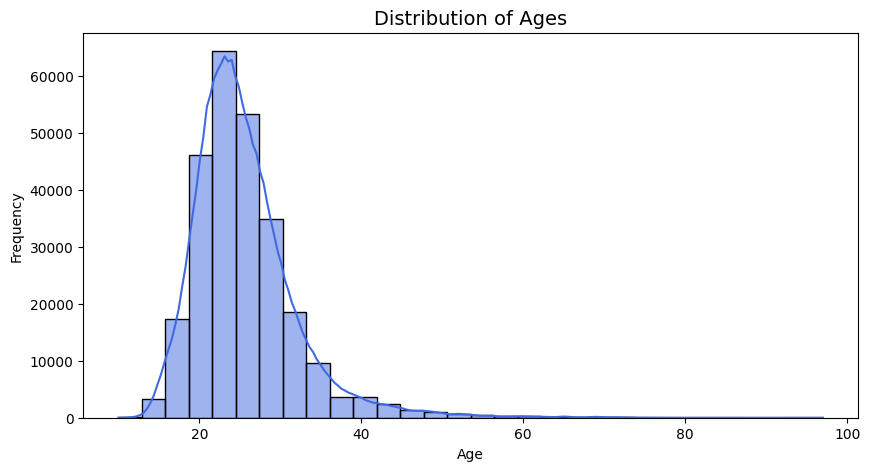

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(df['Age'].dropna(), bins=30, kde=True, color='royalblue')
plt.title('Distribution of Ages', fontsize=14)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

## 3. Box Plot :
This box plot displays the median and spread of athletes' ages, highlighting the older athletes as individual outlier points on the higher end.

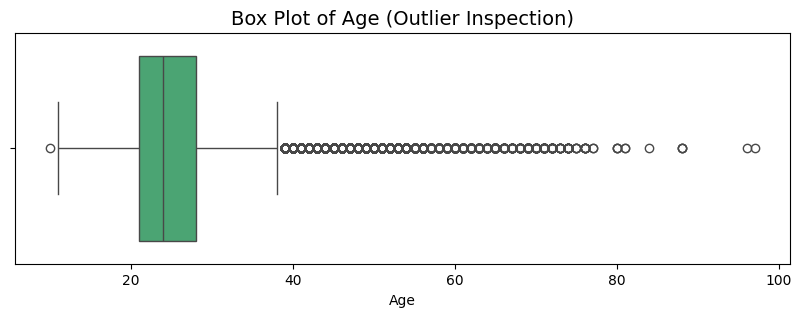

In [ ]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=df['Age'], color='mediumseagreen')
plt.title('Box Plot of Age (Outlier Inspection)', fontsize=14)
plt.xlabel('Age')
plt.show()

## 4.1 Scatter Plot :
This scatter plot illustrates the positive linear relationship between athletes' height and weight.

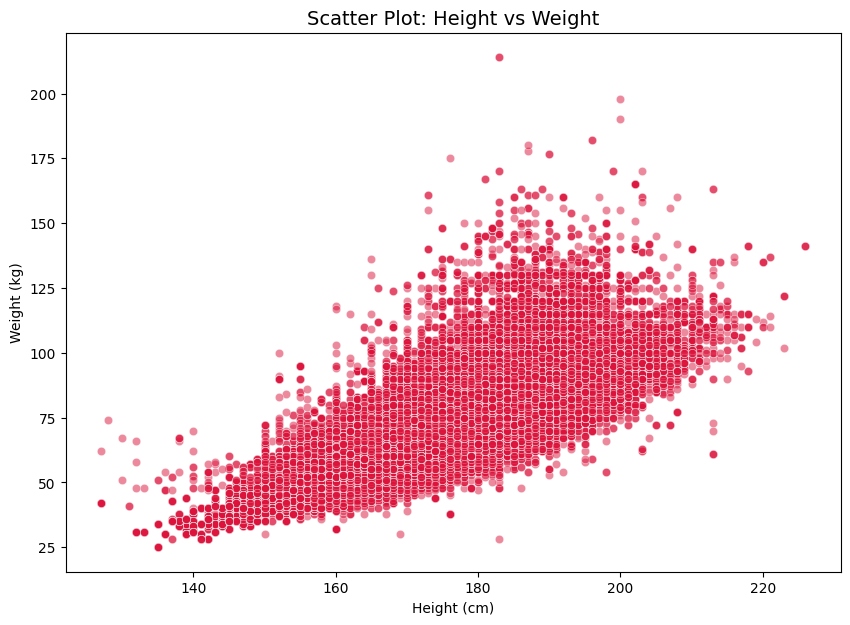

In [ ]:
plt.figure(figsize=(10,7))
sns.scatterplot(x=df['Height'], y=df['Weight'], color='crimson', alpha=0.5)
plt.title('Scatter Plot: Height vs Weight', fontsize=14)
plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.show()

Faheem M 2427010572

## 4.2 Pair Plot :
This grid provides a comprehensive overview of the dataset by plotting pairwise relationships and individual distributions for all numerical features simultaneously.

In [ ]:
pairplot_cols = ['Age', 'Height', 'Weight', 'Medal_Binary']

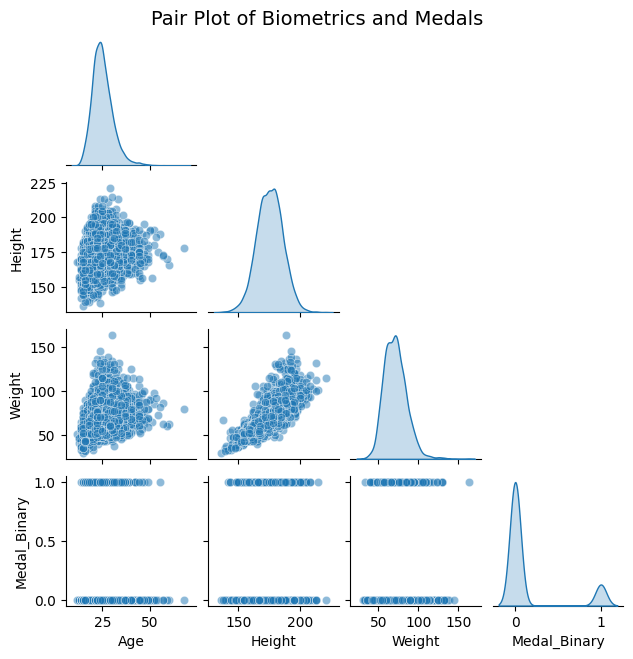

In [ ]:
g = sns.pairplot(df[pairplot_cols].dropna().sample(5000, random_state=42),
                 diag_kind='kde', corner=True, height=1.6, plot_kws={'alpha': 0.5})
g.fig.suptitle('Pair Plot of Biometrics and Medals', y=1.02, fontsize=14)
plt.show()

Faheem M 2427010572

## 5. Correlation Heatmap :
This heatmap uses color intensity to quantify the strength and direction of linear relationships between numerical variables, helping to identify highly correlated features.

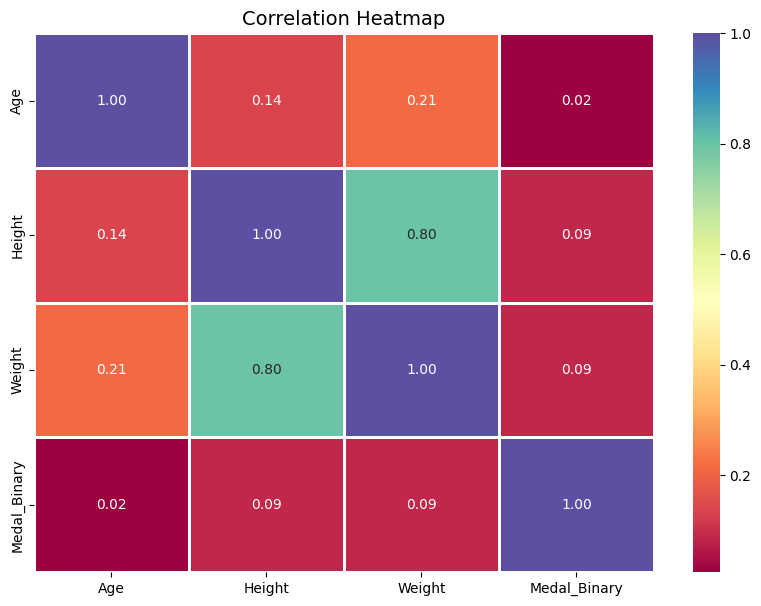

In [ ]:
plt.figure(figsize=(10,7))

cols_to_correlate = ['Age', 'Height', 'Weight', 'Medal_Binary']
corr_matrix = df[cols_to_correlate].corr()

sns.heatmap(corr_matrix, annot=True, cmap='Spectral', fmt=".2f", linewidths=1)
plt.title('Correlation Heatmap', fontsize=14)
plt.show()